# AI-Based Surveillance System for Threat Detection in Defense Environments
### Michael Akrobo Kofi Etornam — 2526500148

This notebook implements the system described in **Chapter 3 (Methodology)** at a scope that is
realistically achievable on a MacBook M4 (Apple Silicon, MPS backend, no CUDA), and produces the
numbers/tables needed for **Chapter 4 (Data Analysis and Findings)**.

**Pipeline (mirrors the 3-layer framework, Section 2.10 / 3.3):**
1. Environment setup
2. Data sourcing (your own filmed clips + optional public benchmark subset)
3. Detection layer — YOLOv8 (pretrained, person class) → optional light fine-tuning
4. Behavior-analysis layer — ResNet-50 feature extractor + LSTM, 4 classes
5. Decision layer — simple rule stub (zone + behavior → alert)
6. Evaluation — the exact metrics needed for Tables 4.2–4.6
7. Real-time benchmarking (FPS / latency)

> **Honesty note for your write-up:** this is a scoped-down prototype (dozens–hundreds of clips,
> not the ~5,000-clip target in Section 3.8). That's normal for an MSc dissertation and Chapter 4
> already anticipates you documenting deviations from the Chapter 3 plan — just say so explicitly
> in Section 4.3.

> **Run order matters.** Each section depends on variables created by the ones before it. Use
> **Kernel → Restart & Run All** rather than re-running individual cells out of sequence — most
> confusing errors (`NameError`, `IndexError`) come from skipping ahead or re-running a later
> cell before an earlier one has produced its data. Before you have real clips, Sections 5
> onward will fail on purpose with a clear message telling you to go back to Section 2 first.


## 1. Environment Setup

In [1]:
# Run once. On macOS this installs the CPU/MPS build of torch automatically.
%pip install ultralytics torch torchvision opencv-python scikit-learn matplotlib seaborn pandas tqdm --quiet


Note: you may need to restart the kernel to use updated packages.


In [1]:
import torch, cv2, os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.chdir("/Users/mikie/Desktop/ML/MSCfinalyear")

# Apple Silicon GPU backend
device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
print("Using device:", device)

Using device: mps


## 2. Sourcing Data

You have two complementary sources — use both if you can, but Option A alone is enough to get a
real prototype running.

### Option A — Film your own clips (recommended, start here)
Using a phone or webcam, record ~5–15 second clips outdoors (a fenced yard, campus perimeter,
gate, or similar restricted-looking area) acting out each class. Aim for at least ~15–20 clips per
class to start (you can add more later):

- **Intrusion** — a person crossing into a marked/roped-off zone
- **Loitering** — a person standing/lingering in one spot for an extended period
- **Anomalous movement** — running, crouching, erratic or fast movement
- **Normal activity** — walking normally through the open area, not entering the restricted zone

Vary lighting (day/dusk if possible), camera angle, and who's in frame — this directly supports the
domain-adaptation argument in Sections 2.4.4/3.5.

Save clips into this folder structure:

```
data/raw_clips/
    intrusion/clip_001.mp4 ...
    loitering/clip_001.mp4 ...
    anomalous/clip_001.mp4 ...
    normal/clip_001.mp4 ...
```

### Option B — Public benchmark subsets (supplementary)
Rather than downloading full UCF-Crime/CUHK Avenue/VIRAT (tens of GB, awkward hosting), pull a
**small labelled subset** from Kaggle, e.g. search Kaggle for "UCF Crime dataset" or "CUHK Avenue
dataset" — several users host trimmed/re-encoded mirrors. Download 10-20 relevant clips per class
and drop them into the same folder structure above. Note in Section 3.9.2 exactly which mirror/
subset you used and how many clips you took, since the original datasets aren't sub-settable in a
citable way otherwise.

Run the cell below once your `data/raw_clips/` folder has content, to sanity-check counts.


In [18]:
print("Current working directory:", os.getcwd())
print("(this is where 'data/raw_clips/...' will be created/looked for below)")


Current working directory: /Users/mikie/Downloads
(this is where 'data/raw_clips/...' will be created/looked for below)


In [19]:
RAW_DIR = "data/raw_clips"
CLASSES = ["intrusion", "loitering", "anomalous", "normal"]

total_clips = 0
for c in CLASSES:
    path = os.path.join(RAW_DIR, c)
    os.makedirs(path, exist_ok=True)
    n = len([f for f in os.listdir(path) if f.lower().endswith((".mp4", ".mov", ".avi"))])
    total_clips += n
    print(f"{c:12s}: {n} clips")

if total_clips == 0:
    print()
    print("!" * 70)
    print("No clips found yet. STOP HERE and do this before continuing:")
    print(f"  1. Note the working directory printed in the cell above.")
    print(f"  2. In Finder, create/open the folders under that path:")
    for c in CLASSES:
        print(f"       {os.path.join(RAW_DIR, c)}")
    print("  3. Drop a few .mp4/.mov/.avi clips into each folder (5+ per class to start).")
    print("  4. Re-run THIS cell — counts should become non-zero.")
    print("  5. Only then continue to Section 3 onward.")
    print("!" * 70)


intrusion   : 8 clips
loitering   : 9 clips
anomalous   : 7 clips
normal      : 9 clips


## 3. Detection Layer — YOLOv8 Person Detection

We use the pretrained YOLOv8 model (COCO weights, includes 'person' class) directly. This matches
the transfer-learning rationale of Section 2.4.4. If you have time later, you can fine-tune on a
small hand-labelled subset — instructions at the end of this section — but pretrained is a
legitimate and honest choice to report in Section 4.3.


In [20]:
from ultralytics import YOLO

detector = YOLO("yolov8n.pt")  # nano model: fastest, good enough for person detection on CPU/MPS
PERSON_CLASS_ID = 0  # COCO class id for 'person'

def detect_persons(frame):
    """Runs YOLOv8 on a single frame, returns list of (x1,y1,x2,y2,conf) for detected persons."""
    results = detector.predict(frame, classes=[PERSON_CLASS_ID], verbose=False, device=device.type)
    boxes = []
    for r in results:
        for b in r.boxes:
            x1, y1, x2, y2 = b.xyxy[0].tolist()
            conf = float(b.conf[0])
            boxes.append((int(x1), int(y1), int(x2), int(y2), conf))
    return boxes


**Optional fine-tuning (only if you hand-label a small set of frames in CVAT/Roboflow and export
YOLO-format annotations):**
```python
detector.train(data="data/yolo_dataset/data.yaml", epochs=20, imgsz=640, device=device.type)
```
Report whichever path you take (pretrained-only vs fine-tuned) explicitly in Section 4.3 — this is
exactly the kind of deviation-from-plan note Chapter 4 asks you to make.

## 4. Frame Extraction & Preprocessing (Section 3.10.1)

Extract frames at a fixed rate, crop to the detected person region, resize, and build fixed-length
sequences for the behavior classifier.


In [21]:
FRAME_RATE = 5          # sampled fps (5 is plenty for behavior over a few seconds; 25 as in
                         # Section 3.10.1 is unnecessary for a prototype and much slower to process)
SEQ_LEN = 16             # frames per sequence fed to the LSTM
IMG_SIZE = 224           # ResNet-50 input size

def extract_person_sequence(video_path, seq_len=SEQ_LEN, img_size=IMG_SIZE):
    """Samples frames from a clip, detects the largest person box in each, crops+resizes it,
    and returns a (seq_len, img_size, img_size, 3) array. Pads/truncates to seq_len."""
    cap = cv2.VideoCapture(video_path)
    native_fps = cap.get(cv2.CAP_PROP_FPS) or 25
    step = max(int(round(native_fps / FRAME_RATE)), 1)

    frames = []
    idx = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if idx % step == 0:
            boxes = detect_persons(frame)
            if boxes:
                # take the largest box (most likely the main subject)
                x1, y1, x2, y2, conf = max(boxes, key=lambda b: (b[2]-b[0])*(b[3]-b[1]))
                crop = frame[max(y1,0):y2, max(x1,0):x2]
                if crop.size > 0:
                    crop = cv2.resize(crop, (img_size, img_size))
                    frames.append(crop)
        idx += 1
    cap.release()

    if len(frames) == 0:
        return None  # no person detected in this clip at all — flag for review

    frames = np.array(frames, dtype=np.float32) / 255.0
    # pad/truncate to fixed sequence length
    if len(frames) >= seq_len:
        frames = frames[:seq_len]
    else:
        pad = np.zeros((seq_len - len(frames), img_size, img_size, 3), dtype=np.float32)
        frames = np.concatenate([frames, pad], axis=0)
    return frames


## 5. Build the Labelled Dataset

In [22]:
from tqdm import tqdm

X, y = [], []
label_map = {c: i for i, c in enumerate(CLASSES)}
skipped = []


for c in CLASSES:
    folder = os.path.join(RAW_DIR, c)
    files = [f for f in os.listdir(folder) if f.lower().endswith((".mp4", ".mov", ".avi"))]
    for f in tqdm(files, desc=c):
        seq = extract_person_sequence(os.path.join(folder, f))
        if seq is None:
            skipped.append((c, f))
            continue
        X.append(seq)
        y.append(label_map[c])

X = np.array(X)
y = np.array(y)
print("Dataset shape:", X.shape, "Labels shape:", y.shape)
print("Skipped (no person detected):", skipped)

assert len(X) > 0, (
    "No clips were successfully processed. Either data/raw_clips/ is still empty "
    "(go back to Section 2), or YOLOv8 never detected a person in any clip "
    "(check that a person is clearly visible/in-frame in your footage)."
)

# save the raw counts now — this is your Table 4.1 data
counts = pd.Series(y).map({v: k for k, v in label_map.items()}).value_counts()
print(counts)


normal: 100%|████████████████████████████████████| 9/9 [00:03<00:00,  2.60it/s]

Dataset shape: (30, 16, 224, 224, 3) Labels shape: (30,)
Skipped (no person detected): [('intrusion', 'clip_002.mp4'), ('anomalous', 'clip_001.mp4'), ('normal', 'clip_002.mp4')]
loitering    9
normal       8
intrusion    7
anomalous    6
Name: count, dtype: int64


In [23]:
from sklearn.model_selection import train_test_split

assert len(np.unique(y)) >= 2, (
    "Need at least 2 classes represented in the dataset to split/stratify and train. "
    "Add clips for the missing class(es) and re-run Section 5."
)
assert len(X) >= 8, (
    f"Only {len(X)} usable clips found — too few to split into train/val/test meaningfully. "
    "Add more clips per class (aim for 5+ each to start) and re-run Section 5."
)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print("Train:", X_train.shape[0], " Val:", X_val.shape[0], " Test:", X_test.shape[0])

# --- This block gives you the numbers for Table 4.1 ---
for name, arr in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(name, pd.Series(arr).map({v: k for k, v in label_map.items()}).value_counts().to_dict())


Train: 21  Val: 4  Test: 5
train {'normal': 6, 'loitering': 6, 'intrusion': 5, 'anomalous': 4}
val {'normal': 1, 'loitering': 1, 'anomalous': 1, 'intrusion': 1}
test {'loitering': 2, 'intrusion': 1, 'anomalous': 1, 'normal': 1}


## 6. Behavior-Analysis Layer — CNN (ResNet-50) + LSTM (Section 3.10.2)

In [24]:
import torch.nn as nn
from torchvision import models, transforms

class CNNLSTM(nn.Module):
    def __init__(self, num_classes=4, hidden_size=256, lstm_layers=1, freeze_cnn=True):
        super().__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        resnet.fc = nn.Identity()  # remove classification head -> 2048-d features
        self.cnn = resnet
        if freeze_cnn:
            for p in self.cnn.parameters():
                p.requires_grad = False
        self.lstm = nn.LSTM(input_size=2048, hidden_size=hidden_size,
                             num_layers=lstm_layers, batch_first=True)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x: (batch, seq_len, 3, H, W)
        b, t, c, h, w = x.shape
        x = x.view(b * t, c, h, w)
        feats = self.cnn(x)                # (b*t, 2048)
        feats = feats.view(b, t, -1)        # (b, t, 2048)
        out, _ = self.lstm(feats)           # (b, t, hidden)
        last = out[:, -1, :]                # final timestep
        return self.classifier(last)

model = CNNLSTM(num_classes=len(CLASSES)).to(device)
print(model)


CNNLSTM(
  (cnn): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
    

In [25]:
from torch.utils.data import Dataset, DataLoader

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

class ClipDataset(Dataset):
    def __init__(self, X, y):
        self.X = X  # (N, seq_len, H, W, 3) floats 0-1
        self.y = y
        self.norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        clip = torch.from_numpy(self.X[i]).permute(0, 3, 1, 2).float()  # (T,3,H,W)
        clip = torch.stack([self.norm(frame) for frame in clip])
        label = int(self.y[i])
        return clip, label

train_ds = ClipDataset(X_train, y_train)
val_ds   = ClipDataset(X_val, y_val)
test_ds  = ClipDataset(X_test, y_test)

BATCH_SIZE = 4  # small batch — sensible default for M4 memory; raise if you have headroom
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE)


## 7. Training Loop

In [26]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)

EPOCHS = 15  # start small; raise once you confirm the pipeline runs end-to-end
history = {"train_loss": [], "val_loss": [], "val_acc": []}

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    for clips, labels in train_loader:
        clips, labels = clips.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(clips)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * clips.size(0)
    train_loss = running_loss / len(train_ds)

    model.eval()
    val_loss, correct = 0.0, 0
    with torch.no_grad():
        for clips, labels in val_loader:
            clips, labels = clips.to(device), labels.to(device)
            outputs = model(clips)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * clips.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
    val_loss /= len(val_ds)
    val_acc = correct / len(val_ds)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    print(f"Epoch {epoch+1}/{EPOCHS}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")


Epoch 1/15  train_loss=1.5352  val_loss=1.4679  val_acc=0.2500
Epoch 2/15  train_loss=1.2060  val_loss=1.4400  val_acc=0.2500
Epoch 3/15  train_loss=1.0090  val_loss=1.3660  val_acc=0.2500
Epoch 4/15  train_loss=0.9185  val_loss=1.3461  val_acc=0.5000
Epoch 5/15  train_loss=0.7134  val_loss=1.3653  val_acc=0.5000
Epoch 6/15  train_loss=0.7996  val_loss=1.3937  val_acc=0.5000
Epoch 7/15  train_loss=0.5575  val_loss=1.4790  val_acc=0.5000
Epoch 8/15  train_loss=0.6095  val_loss=1.1943  val_acc=0.5000
Epoch 9/15  train_loss=0.4186  val_loss=1.2430  val_acc=0.5000
Epoch 10/15  train_loss=0.3942  val_loss=1.3158  val_acc=0.2500
Epoch 11/15  train_loss=0.3799  val_loss=1.3196  val_acc=0.5000
Epoch 12/15  train_loss=0.1884  val_loss=1.1881  val_acc=0.5000
Epoch 13/15  train_loss=0.2065  val_loss=1.5379  val_acc=0.5000
Epoch 14/15  train_loss=0.1031  val_loss=1.2813  val_acc=0.5000
Epoch 15/15  train_loss=0.1636  val_loss=1.0217  val_acc=0.2500


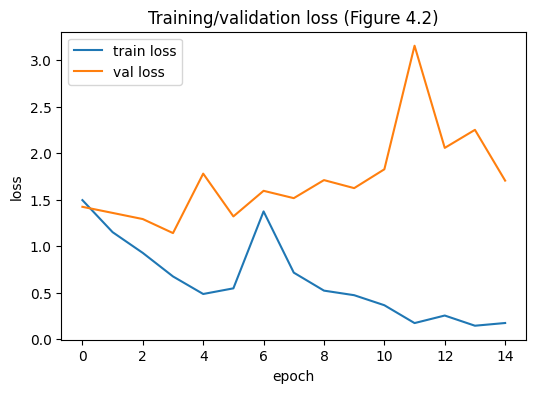

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.plot(history["train_loss"], label="train loss")
plt.plot(history["val_loss"], label="val loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Training/validation loss (Figure 4.2)")
plt.savefig("outputs/fig_4_2_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Behavior Classification Evaluation — fills Tables 4.3 / 4.4

              precision    recall  f1-score   support

   intrusion      0.000     0.000     0.000         1
   loitering      1.000     0.500     0.667         2
   anomalous      0.000     0.000     0.000         1
      normal      1.000     1.000     1.000         1

    accuracy                          0.400         5
   macro avg      0.500     0.375     0.417         5
weighted avg      0.600     0.400     0.467         5

AUC-ROC (macro, one-vs-rest): 0.625


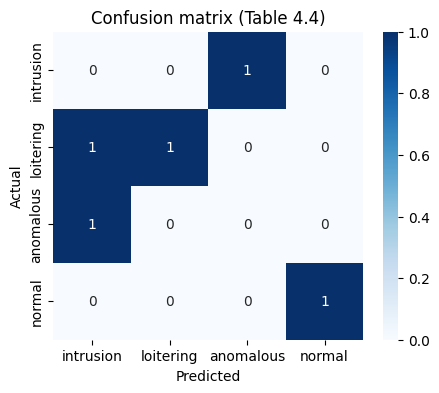

In [27]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns

model.eval()
all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for clips, labels in test_loader:
        clips = clips.to(device)
        outputs = model(clips)
        probs = torch.softmax(outputs, dim=1).cpu().numpy()
        preds = probs.argmax(axis=1)
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
        all_probs.extend(probs)

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

print(classification_report(all_labels, all_preds, target_names=CLASSES, digits=3))
# -> gives you precision/recall/F1 per class AND overall for Table 4.3

try:
    auc = roc_auc_score(all_labels, all_probs, multi_class="ovr")
    print("AUC-ROC (macro, one-vs-rest):", auc)
except ValueError as e:
    print("AUC-ROC could not be computed (often due to a class missing from the test set):", e)

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (Table 4.4)")
plt.savefig("outputs/table_4_4_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
# cm here IS Table 4.4 — just transcribe the numbers


## 9. Detection Layer Evaluation — fills Table 4.2 (mAP@0.5)

To get mAP@0.5 properly you need a small YOLO-format labelled validation set (bounding boxes,
not just class labels). If you fine-tuned YOLOv8 in Section 3, `val()` reports this directly. If
you're using the pretrained model only, hand-label ~30-50 frames in CVAT/Roboflow (export as YOLO
format), point `data.yaml` at them, and run:


In [28]:
# Only run this once you have a YOLO-format val set, e.g. data/yolo_val/data.yaml
# metrics = detector.val(data="data/yolo_val/data.yaml")
# print(metrics.box.map50)       # -> mAP@0.5 for Table 4.2
# print(metrics.box.p, metrics.box.r)  # precision/recall for the person class


## 10. Real-Time Performance — fills Table 4.5

In [29]:
import time

def measure_fps(video_path, n_frames=100):
    cap = cv2.VideoCapture(video_path)
    latencies = []
    count = 0
    while count < n_frames:
        ret, frame = cap.read()
        if not ret:
            break
        t0 = time.time()
        _ = detect_persons(frame)
        latencies.append(time.time() - t0)
        count += 1
    cap.release()
    latencies = np.array(latencies)
    return latencies.mean() * 1000, 1.0 / latencies.mean()  # ms, fps

_candidates = [f for f in os.listdir(os.path.join(RAW_DIR, CLASSES[0]))
               if f.lower().endswith((".mp4", ".mov", ".avi"))]
assert _candidates, (
    f"No video files found in {os.path.join(RAW_DIR, CLASSES[0])}. "
    "Make sure Section 2 shows non-zero clip counts before running this cell."
)
sample_clip = os.path.join(RAW_DIR, CLASSES[0], _candidates[0])
avg_latency_ms, fps = measure_fps(sample_clip)
print(f"Average latency: {avg_latency_ms:.2f} ms/frame  |  Throughput: {fps:.2f} FPS")
print("Hardware: Apple M4 (MPS backend)" if device.type == "mps" else "Hardware: CPU")
# -> these three numbers are your Table 4.5


Average latency: 20.48 ms/frame  |  Throughput: 48.83 FPS
Hardware: Apple M4 (MPS backend)


## 11. Decision Layer (Section 3.3) — simple rule stub

This doesn't need machine learning — it's the rule-based logic described in Section 3.3/3.11 that
turns a classified behavior + zone into an alert, keeping a human in the loop.


In [30]:
RESTRICTED_ZONES = {"gate_area", "perimeter_fence"}  # example zone ids for your simulated site

def decide_alert(behavior_label, zone_id):
    """Returns True (raise alert for human review) or False, per the decision-layer logic
    described in Sections 3.3 and 3.11. Normal activity never alerts; the other three classes
    alert only when the zone is restricted."""
    if behavior_label == "normal":
        return False
    return zone_id in RESTRICTED_ZONES

# example
print(decide_alert("loitering", "gate_area"))   # True -> alert raised for operator review
print(decide_alert("normal", "gate_area"))      # False


True
False


## 12. Environmental Breakdown — Section 4.7 / Figure 4.4

If you tagged clips with lighting condition when filming (e.g. filename suffix `_day`, `_dusk`,
`_night`), you can break accuracy down by condition here. Otherwise, skip this until you've
collected condition-tagged clips.


In [31]:
# Example if you name files like intrusion_clip01_day.mp4, intrusion_clip02_night.mp4 etc.
# You'd need to carry the condition label through the dataset-building step (Section 5) alongside y.
# Sketch:
#
# condition_acc = {}
# for cond in ["day", "dusk", "night"]:
#     idx = [i for i in range(len(test_files)) if cond in test_files[i]]
#     if idx:
#         acc = (all_preds[idx] == all_labels[idx]).mean()
#         condition_acc[cond] = acc
# print(condition_acc)


## 13. Save Everything Needed for Chapter 4 / 5

Run this last to dump a JSON summary you can paste straight into your Chapter 4 tables.


In [32]:
os.makedirs("outputs", exist_ok=True)
torch.save(model.state_dict(), "outputs/cnn_lstm.pt")
print("Model saved to outputs/cnn_lstm.pt")

summary = {
    "dataset_counts": counts.to_dict(),
    "train_val_test_sizes": {"train": len(y_train), "val": len(y_val), "test": len(y_test)},
    "classification_report": classification_report(all_labels, all_preds, target_names=CLASSES, output_dict=True),
    "confusion_matrix": cm.tolist(),
    "real_time_performance": {"avg_latency_ms": avg_latency_ms, "fps": fps, "hardware": "Apple M4 (MPS)"},
}

with open("outputs/chapter4_results_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved outputs/chapter4_results_summary.json")
print(json.dumps(summary, indent=2)[:1000], "...")


Model saved to outputs/cnn_lstm.pt
Saved outputs/chapter4_results_summary.json
{
  "dataset_counts": {
    "loitering": 9,
    "normal": 8,
    "intrusion": 7,
    "anomalous": 6
  },
  "train_val_test_sizes": {
    "train": 21,
    "val": 4,
    "test": 5
  },
  "classification_report": {
    "intrusion": {
      "precision": 0.0,
      "recall": 0.0,
      "f1-score": 0.0,
      "support": 1.0
    },
    "loitering": {
      "precision": 1.0,
      "recall": 0.5,
      "f1-score": 0.6666666666666666,
      "support": 2.0
    },
    "anomalous": {
      "precision": 0.0,
      "recall": 0.0,
      "f1-score": 0.0,
      "support": 1.0
    },
    "normal": {
      "precision": 1.0,
      "recall": 1.0,
      "f1-score": 1.0,
      "support": 1.0
    },
    "accuracy": 0.4,
    "macro avg": {
      "precision": 0.5,
      "recall": 0.375,
      "f1-score": 0.41666666666666663,
      "support": 5.0
    },
    "weighted avg": {
      "precision": 0.6,
      "recall": 0.4,
      "f1-score"